we are going to solve a small optimization problem using the Quantum Approximate Optimization Algorithm, or QAOA. The goal is to see how a quantum circuit and a classical optimizer work together to find a high-quality solution to a Max-Cut problem.

In [2]:
import numpy as np
import networkx as nx

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from scipy.optimize import minimize

In [3]:
graph = nx.Graph()

graph.add_edges_from([
    (0, 1),
    (1, 2),
    (0, 2)
])

print("Nodes:", graph.nodes())
print("Edges:", graph.edges())

Nodes: [0, 1, 2]
Edges: [(0, 1), (0, 2), (1, 2)]


In [4]:
def maxcut_cost(bitstring, graph):
    cost = 0

    for node_a, node_b in graph.edges():
        if bitstring[node_a] != bitstring[node_b]:
            cost += 1

    return cost

In [5]:
for value in range(8):
    bitstring = format(value, "03b")

    cost = maxcut_cost(bitstring, graph)

    print(
        f"{bitstring} -> Cut value = {cost}"
    )

000 -> Cut value = 0
001 -> Cut value = 2
010 -> Cut value = 2
011 -> Cut value = 2
100 -> Cut value = 2
101 -> Cut value = 2
110 -> Cut value = 2
111 -> Cut value = 0


In [6]:
def build_qaoa_circuit(gamma, beta):
    circuit = QuantumCircuit(3, 3)

    # Create equal superposition
    circuit.h([0, 1, 2])

    # Cost layer
    for qubit_a, qubit_b in graph.edges():
        circuit.cx(qubit_a, qubit_b)
        circuit.rz(2 * gamma, qubit_b)
        circuit.cx(qubit_a, qubit_b)

    # Mixer layer
    for qubit in range(3):
        circuit.rx(2 * beta, qubit)

    circuit.measure([0, 1, 2], [0, 1, 2])

    return circuit

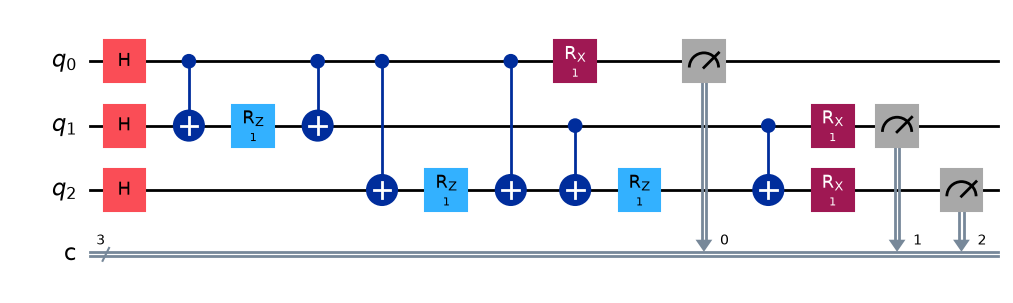

In [7]:
example_circuit = build_qaoa_circuit(
    gamma=0.5,
    beta=0.5
)

example_circuit.draw("mpl")

In [8]:
simulator = AerSimulator()

In [9]:
def qaoa_expectation(parameters):
    gamma, beta = parameters

    circuit = build_qaoa_circuit(
        gamma,
        beta
    )

    result = simulator.run(
        circuit,
        shots=2000
    ).result()

    counts = result.get_counts()

    total_shots = sum(counts.values())

    expected_cost = 0

    for bitstring, count in counts.items():
        reversed_bits = bitstring[::-1]

        cost = maxcut_cost(
            reversed_bits,
            graph
        )

        expected_cost += (
            cost * count / total_shots
        )

    return -expected_cost

In [10]:
initial_parameters = [
    0.5,
    0.5
]

initial_value = qaoa_expectation(
    initial_parameters
)

print(
    f"Initial expected cut value: "
    f"{-initial_value:.3f}"
)

Initial expected cut value: 0.139


In [11]:
optimization_result = minimize(
    qaoa_expectation,
    initial_parameters,
    method="COBYLA",
    options={
        "maxiter": 40
    }
)

print(optimization_result)

 message: Return from COBYLA because the trust region radius reaches its lower bound.
 success: True
  status: 0
     fun: -1.9969999999999999
       x: [ 1.228e+00  2.857e-01]
    nfev: 33
   maxcv: 0.0


In [12]:
optimal_gamma = optimization_result.x[0]
optimal_beta = optimization_result.x[1]

print(
    f"Optimal gamma: "
    f"{optimal_gamma:.4f}"
)

print(
    f"Optimal beta: "
    f"{optimal_beta:.4f}"
)

print(
    f"Optimized expected cut value: "
    f"{-optimization_result.fun:.3f}"
)

Optimal gamma: 1.2279
Optimal beta: 0.2857
Optimized expected cut value: 1.997


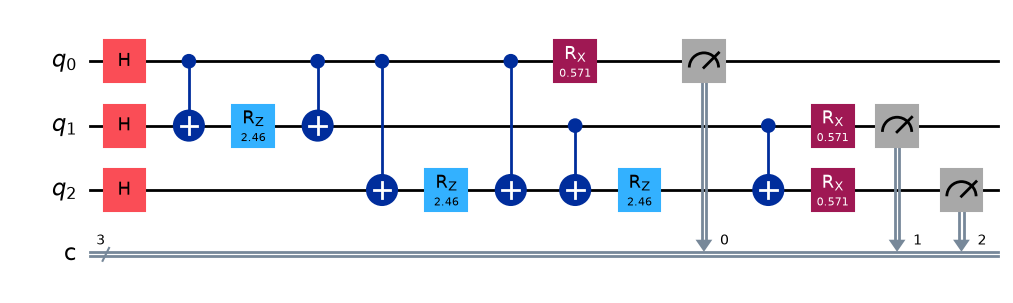

In [13]:
optimized_circuit = build_qaoa_circuit(
    optimal_gamma,
    optimal_beta
)

optimized_circuit.draw("mpl")

In [14]:
final_result = simulator.run(
    optimized_circuit,
    shots=5000
).result()

final_counts = final_result.get_counts()

print(final_counts)

{'011': 815, '101': 826, '010': 841, '110': 841, '001': 848, '100': 812, '000': 11, '111': 6}


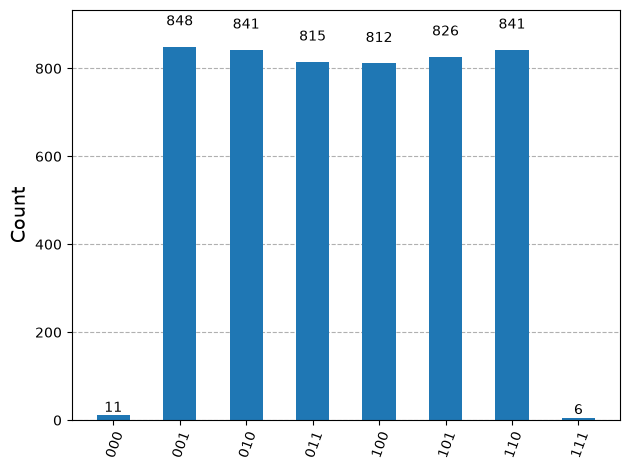

In [15]:
plot_histogram(final_counts)

In [16]:
candidate_results = []

for bitstring, count in final_counts.items():
    bits = bitstring[::-1]

    cost = maxcut_cost(
        bits,
        graph
    )

    candidate_results.append(
        (
            bits,
            cost,
            count
        )
    )

candidate_results = sorted(
    candidate_results,
    key=lambda item: (
        item[1],
        item[2]
    ),
    reverse=True
)

for bits, cost, count in candidate_results:
    print(
        f"{bits} -> "
        f"Cut value = {cost}, "
        f"Measurements = {count}"
    )

100 -> Cut value = 2, Measurements = 848
010 -> Cut value = 2, Measurements = 841
011 -> Cut value = 2, Measurements = 841
101 -> Cut value = 2, Measurements = 826
110 -> Cut value = 2, Measurements = 815
001 -> Cut value = 2, Measurements = 812
000 -> Cut value = 0, Measurements = 11
111 -> Cut value = 0, Measurements = 6


In [17]:
best_solution = candidate_results[0]

best_bits = best_solution[0]
best_cost = best_solution[1]

print(
    f"Best QAOA solution: "
    f"{best_bits}"
)

print(
    f"Best cut value: "
    f"{best_cost}"
)

Best QAOA solution: 100
Best cut value: 2


In [18]:
classical_best_cost = 0
classical_best_states = []

for value in range(8):
    bitstring = format(value, "03b")

    cost = maxcut_cost(
        bitstring,
        graph
    )

    if cost > classical_best_cost:
        classical_best_cost = cost
        classical_best_states = [
            bitstring
        ]

    elif cost == classical_best_cost:
        classical_best_states.append(
            bitstring
        )

print(
    f"Classical optimal cut value: "
    f"{classical_best_cost}"
)

print(
    "Classical optimal states:",
    classical_best_states
)

Classical optimal cut value: 2
Classical optimal states: ['001', '010', '011', '100', '101', '110']
